In [1]:
import numpy as np

SKI_CONF_MIN = 0.15  # pseudo ski keypoints below this are treated as missing


def compute_skier_orientation_features(keypoints_21):
    """
    Computes body angle, ski orientations, and grab distances from a [21, 3] frame keypoint array.
    keypoints_21: [21, (x, y, conf)]
    Returns: dict of derived physical metrics
    """
    kpts = keypoints_21[:, :2]
    confs = keypoints_21[:, 2] if keypoints_21.shape[1] > 2 else np.ones(len(keypoints_21))

    # --- 1. Body Orientation Angle (Spine Vector) ---
    l_shoulder, r_shoulder = kpts[5], kpts[6]
    l_hip, r_hip = kpts[11], kpts[12]

    shoulder_center = (l_shoulder + r_shoulder) / 2.0
    hip_center = (l_hip + r_hip) / 2.0
    spine_vec = shoulder_center - hip_center  # Vector pointing from hips to shoulders

    # Angle relative to vertical axis (in degrees, -180 to 180)
    body_angle = np.degrees(np.arctan2(spine_vec[0], -spine_vec[1]))

    # --- 2. Ski Angles & Relative Crossing Angle ---
    l_ski_tip, l_ski_tail = kpts[17], kpts[18]
    r_ski_tip, r_ski_tail = kpts[19], kpts[20]
    left_ok = confs[17] >= SKI_CONF_MIN and confs[18] >= SKI_CONF_MIN
    right_ok = confs[19] >= SKI_CONF_MIN and confs[20] >= SKI_CONF_MIN

    l_ski_vec = l_ski_tip - l_ski_tail
    r_ski_vec = r_ski_tip - r_ski_tail

    angle_l_ski = np.degrees(np.arctan2(l_ski_vec[1], l_ski_vec[0])) if left_ok else np.nan
    angle_r_ski = np.degrees(np.arctan2(r_ski_vec[1], r_ski_vec[0])) if right_ok else np.nan

    # Absolute crossing angle between the two skis
    if left_ok and right_ok:
        dot_product = np.dot(l_ski_vec, r_ski_vec)
        norms = np.linalg.norm(l_ski_vec) * np.linalg.norm(r_ski_vec)
        if norms > 1e-6:
            cos_angle = np.clip(dot_product / norms, -1.0, 1.0)
            crossed_ski_angle = np.degrees(np.arccos(cos_angle))
        else:
            crossed_ski_angle = 0.0
    else:
        crossed_ski_angle = np.nan

    # --- 3. Grab Distances (Wrist to Ski Tip/Tail) ---
    l_wrist, r_wrist = kpts[9], kpts[10]
    left_hand_ski_dist = min(
        np.linalg.norm(l_wrist - l_ski_tip) if left_ok else np.inf,
        np.linalg.norm(l_wrist - r_ski_tip) if right_ok else np.inf
    )
    right_hand_ski_dist = min(
        np.linalg.norm(r_wrist - l_ski_tip) if left_ok else np.inf,
        np.linalg.norm(r_wrist - r_ski_tip) if right_ok else np.inf
    )
    if not np.isfinite(min(left_hand_ski_dist, right_hand_ski_dist)):
        min_grab = np.nan
    else:
        min_grab = float(min(left_hand_ski_dist, right_hand_ski_dist))

    return {
        "body_angle": body_angle,
        "l_ski_angle": angle_l_ski,
        "r_ski_angle": angle_r_ski,
        "crossed_ski_angle": crossed_ski_angle,
        "min_grab_dist": min_grab
    }

## Ski detection (classical CV, no labels)

The pose model only predicts COCO body joints, so skis are found separately inside each tracked skier ROI.
The implementation lives in `ski_detector.py` (next to this notebook):

1. crop a square region centred on the ankles (bbox fallback when pose is missing),
2. enhance contrast and run LSD line-segment detection,
3. merge collinear fragments and keep the best nearly-parallel pair near the boots,
4. smooth angle / centre / length over time and carry the pair through short occlusions,
5. when the pair is lost, propagate the previous skis with Lucas–Kanade optical flow.

The **pose crop** is rotated with the smoothed hips→shoulders axis so the skier stays upright
(`ALIGN_POSE_ROI = True`); this roughly doubled pose coverage on the HD clips. The ski ROI is
left axis-aligned (the rotated variant was tested and was not better), and optical flow carries
the skis through missed frames.

Outputs per clip: `ski_dataset/<stem>_ski.npz` (2 ski quads per frame + confidence/angle/length)
and `roi_pose_dataset/<stem>_pose21.npy` (17 body + 4 pseudo ski keypoints = 21, ready for
`compute_skier_orientation_features`).


In [2]:
# --- Ski detector setup (imports the implementation in ski_detector.py) ---
from pathlib import Path

# Reload ski_detector so edits to the module are picked up without restarting
# the kernel (a stale import is the usual cause of "cannot import name ...").
import importlib
import ski_detector
importlib.reload(ski_detector)

from ski_detector import (SkiDetectorCV, BodyAligner, skis_to_keypoints,
                          attach_ski_keypoints, draw_skis,
                          pose_keypoints_in_roi, make_roi_transform,
                          pose_keypoints_detected_roi, bbox_from_keypoints)

SKI_OUTPUT_DIR = Path("ski_dataset")
SKI_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("SkiDetectorCV ready; ski tracks will be written to", SKI_OUTPUT_DIR.resolve())


SkiDetectorCV ready; ski tracks will be written to C:\Users\franc\Downloads\AQA-7\AQA-7\Actions\ski_big_air\ski_dataset


In [4]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

# ==============================================================================
# 0. CONFIGURATION & INPUT INTEGRITY CHECKS
# ==============================================================================

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
OUTPUT_DIR = Path("roi_pose_dataset")
SKI_OUTPUT_DIR = Path("ski_dataset")   # one .npz of ski tracks per video
DETECT_SKIS = False                    # B1: ski detection is disabled (unreliable)
USE_DETECTED_ROI_POSE = True           # detect person per frame, then refine pose on their ROI
POSE_CONF = 0.1                        # low threshold needed for 320x240 AQA clips
BODY_BOX_PAD = 0.25                    # pad the pose-derived body box by 25%
USE_TEMPORAL_TRACKING = True           # offline Viterbi stitching + gap filling
TEMPORAL_MAX_GAP = 15                  # max frames to bridge between detections
OVERWRITE_POSE = True                  # regenerate pose arrays with temporal tracking
OVERWRITE_SKI = False                  # True re-processes clips that already have skis
ALIGN_POSE_ROI = True                  # rotate the pose crop with the skier's body axis
SKI_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def resolve_video(stem, data_dir=DATA_DIR):
    """Return the first existing video file for a label stem, else None."""
    stem = str(stem)
    candidates = (
        data_dir / f"{stem}.mp4",
        data_dir / f"{stem.zfill(3)}.mp4",
        data_dir / f"{stem.zfill(3)}.avi",
        data_dir / f"{stem}.avi",
    )
    return next((p for p in candidates if p.is_file()), None)

# Load and validate labels
labels = pd.read_csv(DATA_DIR / "labels_CV.csv", sep=",")
errors, warnings = [], []

# Check duplicate filenames
dupes = labels.loc[labels["filename"].astype(str).duplicated(), "filename"].tolist()
if dupes:
    errors.append(f"duplicate filenames in labels_CV.csv: {dupes}")

# Check valid score ranges
bad_targets = labels.loc[~labels["target"].astype(float).between(0, 101), ["filename", "target"]]
if len(bad_targets):
    errors.append(f"targets outside 0-101 range:\n{bad_targets.to_string(index=False)}")

# Resolve video paths
labels["video_path"] = labels["filename"].map(resolve_video)
missing = labels.loc[labels["video_path"].isna(), "filename"].tolist()
if missing:
    errors.append(f"labels with no matching .mp4/.avi file: {missing}")

# Unused files warning
used = {str(p.resolve()) for p in labels["video_path"].dropna()}
on_disk = {p for p in DATA_DIR.iterdir() if p.suffix.lower() in {".mp4", ".avi"}}
unused = sorted(p.name for p in on_disk if str(p.resolve()) not in used)
if unused:
    warnings.append(f"video files with no label row: {unused}")

print(f"labels_CV.csv : {len(labels)} rows, targets {labels['target'].min()}-{labels['target'].max()}")
for msg in warnings:
    print(f"[WARN] {msg}")

if errors:
    print(f"\n{len(errors)} blocking issue(s):")
    for msg in errors:
        print(f"  [ERROR] {msg}")
    raise ValueError("Fix the input issues above before building the dataset.")

print("All input integrity checks passed successfully.\n")


# ==============================================================================
# 1. DYNAMIC TRACKER & MOTION COMPENSATION MODULES
# ==============================================================================

class GlobalMotionCompensator:
    """Estimates camera movement (pan, tilt, zoom) via ORB optical flow."""
    def __init__(self):
        self.prev_gray = None
        self.detector = cv2.ORB_create(nfeatures=500)

    def compensate(self, frame):
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        if self.prev_gray is None:
            self.prev_gray = gray
            return np.eye(2, 3, dtype=np.float32)

        kp1, des1 = self.detector.detectAndCompute(self.prev_gray, None)
        kp2, des2 = self.detector.detectAndCompute(gray, None)

        if des1 is None or des2 is None or len(kp1) < 10 or len(kp2) < 10:
            self.prev_gray = gray
            return np.eye(2, 3, dtype=np.float32)

        matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
        matches = matcher.match(des1, des2)
        matches = sorted(matches, key=lambda x: x.distance)[:50]

        pts1 = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
        pts2 = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)

        M, _ = cv2.estimateAffinePartial2D(pts1, pts2)
        self.prev_gray = gray
        return M if M is not None else np.eye(2, 3, dtype=np.float32)


class DynamicPersonTracker:
    """Tracks target skier across camera motion and performs automatic recovery."""
    def __init__(self, pose_model_path="yolov8n-pose.pt"):
        self.model = YOLO(pose_model_path)
        self.gmc = GlobalMotionCompensator()
        self.tracker = None
        self.bbox = None
        self.is_tracking = False

    def _create_csrt_tracker(self):
        """Robust instantiator for CSRT tracker across different OpenCV versions."""
        if hasattr(cv2, 'TrackerCSRT_create'):
            return cv2.TrackerCSRT_create()
        elif hasattr(cv2, 'legacy') and hasattr(cv2.legacy, 'TrackerCSRT_create'):
            return cv2.legacy.TrackerCSRT_create()
        elif hasattr(cv2, 'TrackerCSRT') and hasattr(cv2.TrackerCSRT, 'create'):
            return cv2.TrackerCSRT.create()
        elif hasattr(cv2, 'TrackerMIL_create'):
            print("  [WARN] CSRT unavailable (OpenCV 5); using MIL tracker instead.")
            return cv2.TrackerMIL_create()
        else:
            raise AttributeError(
                "CSRT Tracker is unavailable. Make sure 'opencv-contrib-python' "
                "is installed correctly: pip install opencv-contrib-python"
            )

    def init_tracker(self, frame, bbox):
        self.bbox = bbox
        self.tracker = self._create_csrt_tracker()
        self.tracker.init(frame, tuple(map(int, bbox)))
        self.is_tracking = True

    def update(self, frame):
        if not self.is_tracking:
            return None, False

        # Apply camera motion shift
        M = self.gmc.compensate(frame)
        if M is not None:
            cx = self.bbox[0] + self.bbox[2] / 2.0
            cy = self.bbox[1] + self.bbox[3] / 2.0
            pts = np.array([[[cx, cy]]], dtype=np.float32)
            transformed = cv2.transform(pts, M)
            new_cx, new_cy = transformed[0][0]
            self.bbox = (new_cx - self.bbox[2] / 2.0, new_cy - self.bbox[3] / 2.0, self.bbox[2], self.bbox[3])

        success, tracked_box = self.tracker.update(frame)
        if success:
            self.bbox = tracked_box
            return self.bbox, True
        else:
            self.is_tracking = False
            return self.bbox, False

    def recover_target(self, frame, prev_bbox, iou_threshold=0.2):
        """Full-frame re-detection fallback when visual tracking drifts."""
        results = self.model(frame, verbose=False, conf=0.1)[0]
        if results.boxes is None or len(results.boxes) == 0:
            return False

        best_iou, best_box = 0.0, None
        px, py, pw, ph = prev_bbox
        p_area = pw * ph

        for box in results.boxes.xywh.cpu().numpy():
            cx, cy, w, h = box
            bx, by = cx - w / 2.0, cy - h / 2.0

            inter_x1, inter_y1 = max(px, bx), max(py, by)
            inter_x2, inter_y2 = min(px + pw, bx + w), min(py + ph, by + h)
            inter_w, inter_h = max(0.0, inter_x2 - inter_x1), max(0.0, inter_y2 - inter_y1)
            inter_area = inter_w * inter_h
            union_area = p_area + (w * h) - inter_area
            iou = inter_area / union_area if union_area > 0 else 0

            if iou > best_iou and iou > iou_threshold:
                best_iou = iou
                best_box = (bx, by, w, h)

        if best_box is not None:
            self.init_tracker(frame, best_box)
            return True
        return False


def remap_crop_keypoints(kpts, scale, pad_x, pad_y, crop_x1, crop_y1):
    """Maps keypoint predictions from 640x640 cropped input back to video space."""
    if kpts is None or len(kpts) == 0:
        return np.array([])
    remapped = kpts.copy()
    remapped[..., 0] = (remapped[..., 0] - pad_x) / scale + crop_x1
    remapped[..., 1] = (remapped[..., 1] - pad_y) / scale + crop_y1
    return remapped


def find_skier_entry_frame(video_path, model, min_conf=0.15, max_scan_frames=150):
    """Scans video until the skier enters the frame."""
    cap = cv2.VideoCapture(str(video_path))
    frame_idx = 0

    while cap.isOpened() and frame_idx < max_scan_frames:
        ret, frame = cap.read()
        if not ret:
            break

        results = model(frame, verbose=False, conf=min_conf)[0]
        if results.boxes is not None and len(results.boxes) > 0:
            persons = [b for b in results.boxes if int(b.cls[0]) == 0 and float(b.conf[0]) >= min_conf]
            if persons:
                best_person = max(persons, key=lambda b: float(b.conf[0]))
                cx, cy, w, h = best_person.xywh.cpu().numpy()[0]
                init_box = (cx - w / 2.0, cy - h / 2.0, w, h)
                cap.release()
                return frame_idx, frame, init_box
        frame_idx += 1

    cap.release()
    return None, None, None


# ==============================================================================
# 2. MAIN DATASET PROCESSING PIPELINE
# ==============================================================================

def process_aqa_dataset(labels_df, output_dir=OUTPUT_DIR):
    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)
    
    if USE_TEMPORAL_TRACKING:
        from temporal_tracker import process_aqa_dataset_temporal
        return process_aqa_dataset_temporal(
            labels_df, output_dir=output_path, ski_output_dir=SKI_OUTPUT_DIR,
            data_dir=DATA_DIR, overwrite=OVERWRITE_POSE,
            max_gap=TEMPORAL_MAX_GAP, pose_conf=POSE_CONF, bbox_pad=BODY_BOX_PAD)
    
    pipeline = DynamicPersonTracker(pose_model_path="yolov8n-pose.pt")
    ski_detector = SkiDetectorCV(align_body=False, flow_propagation=True) if DETECT_SKIS else None
    pose_aligner = BodyAligner() if ALIGN_POSE_ROI else None
    processed_records = []

    for idx, row in labels_df.iterrows():
        video_file = row["video_path"]
        target_score = row["target"]
        stem_name = Path(video_file).stem

        print(f"[{idx+1}/{len(labels_df)}] Processing: {stem_name} (Target Score: {target_score})")

        ski_file = SKI_OUTPUT_DIR / f"{stem_name}_ski.npz"
        if ski_detector is not None and ski_file.exists() and not OVERWRITE_SKI:
            pose_file = output_path / f"{stem_name}_pose.npy"
            n_existing = int(np.load(pose_file).shape[0]) if pose_file.exists() else 0
            print(f"  [SKIP] ski track already exists ({n_existing} frames)")
            processed_records.append({
                "filename": row["filename"],
                "pose_feature_path": str(pose_file),
                "ski_feature_path": str(ski_file),
                "num_frames": n_existing,
                "target": target_score,
            })
            continue
        if ski_detector is not None:
            ski_detector.reset()
        if pose_aligner is not None:
            pose_aligner.reset()

        # Step 1: Scan for skier entry frame
        entry_idx, entry_frame, init_box = find_skier_entry_frame(video_file, pipeline.model)

        if init_box is None:
            print(f"  [SKIP] No skier detected in initial scan of {stem_name}")
            continue

        print(f"  -> Skier detected entering at Frame {entry_idx}")

        frame_h, frame_w = entry_frame.shape[:2]

        # Fill pre-entry frames with zeros / NaNs
        video_keypoints_sequence = [np.zeros((17, 3), dtype=np.float32) for _ in range(entry_idx)]
        video_keypoints21_sequence = [np.zeros((21, 3), dtype=np.float32) for _ in range(entry_idx)]
        empty_quad = np.full((2, 8), np.nan, dtype=np.float32)
        video_ski_quads = [empty_quad.copy() for _ in range(entry_idx)]
        video_ski_conf = [np.zeros(2, dtype=np.float32) for _ in range(entry_idx)]
        video_ski_angle = [np.full(2, np.nan, dtype=np.float32) for _ in range(entry_idx)]
        video_ski_length = [np.zeros(2, dtype=np.float32) for _ in range(entry_idx)]
        video_bboxes = [np.full(4, np.nan, dtype=np.float32) for _ in range(entry_idx)]

        # Step 2: Initialize tracker at entry point
        pipeline.init_tracker(entry_frame, init_box)

        # Open video and fast-forward to entry frame
        cap = cv2.VideoCapture(str(video_file))
        cap.set(cv2.CAP_PROP_POS_FRAMES, entry_idx)

        # Step 3: Process video frames
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            # Body-only B1 mode: full-frame pose, no tracker/ROI drift.
            frame_kpts = np.zeros((17, 3), dtype=np.float32)
            ski_result = {"skis": []}
            frame_quad = np.full((2, 8), np.nan, dtype=np.float32)
            frame_ski_conf = np.zeros(2, dtype=np.float32)
            frame_ski_angle = np.full(2, np.nan, dtype=np.float32)
            frame_ski_length = np.zeros(2, dtype=np.float32)

            if USE_DETECTED_ROI_POSE:
                frame_kpts, pose_bbox = pose_keypoints_detected_roi(
                    pipeline.model, frame, prev_bbox=pipeline.bbox,
                    aligner=pose_aligner,
                    conf_thres=POSE_CONF, bbox_pad=BODY_BOX_PAD)
                if frame_kpts[:, 2].max() > 0 and pose_bbox is not None:
                    bbox = pose_bbox
                    pipeline.bbox = bbox
                    tracking_ok = True
                else:
                    bbox = pipeline.bbox
                    tracking_ok = False
            else:
                bbox, tracking_ok = pipeline.update(frame)
                if not tracking_ok:
                    re_detected = pipeline.recover_target(frame, pipeline.bbox)
                    if re_detected:
                        bbox = pipeline.bbox
                        tracking_ok = True
                if tracking_ok and bbox is not None:
                    frame_kpts = pose_keypoints_in_roi(
                        pipeline.model, frame, bbox,
                        aligner=pose_aligner if ALIGN_POSE_ROI else None)

            # --- classical-CV ski detection on the same tracked ROI ---
            if tracking_ok and bbox is not None and ski_detector is not None:
                have_pose = frame_kpts[:, 2].max() > 0
                ski_result = ski_detector.detect(frame, bbox, frame_kpts if have_pose else None)
                for ski in ski_result["skis"]:
                    slot = 0 if ski["side"] == "left" else 1
                    frame_quad[slot] = ski["quad"].reshape(-1)
                    frame_ski_conf[slot] = ski["conf"]
                    frame_ski_angle[slot] = ski["angle"]
                    frame_ski_length[slot] = ski["length"]

            video_keypoints21_sequence.append(attach_ski_keypoints(frame_kpts, ski_result))
            video_ski_quads.append(frame_quad)
            video_ski_conf.append(frame_ski_conf)
            video_ski_angle.append(frame_ski_angle)
            video_ski_length.append(frame_ski_length)
            video_bboxes.append(np.asarray(bbox if bbox is not None else [np.nan] * 4, dtype=np.float32))
            video_keypoints_sequence.append(frame_kpts)

        cap.release()

        # Step 4: Export arrays
        if len(video_keypoints_sequence) > 0:
            seq_array = np.array(video_keypoints_sequence, dtype=np.float32)  # [T, 17, 3]
            save_file = output_path / f"{stem_name}_pose.npy"
            np.save(save_file, seq_array)

            # 21-keypoint layout expected by compute_skier_orientation_features
            pose21_array = np.array(video_keypoints21_sequence, dtype=np.float32)  # [T, 21, 3]
            np.save(output_path / f"{stem_name}_pose21.npy", pose21_array)

            # ski tracks: 2 skis x 4 quad points, plus confidence / angle / length
            ski_file = SKI_OUTPUT_DIR / f"{stem_name}_ski.npz"
            np.savez_compressed(
                ski_file,
                quads=np.array(video_ski_quads, dtype=np.float32),
                conf=np.array(video_ski_conf, dtype=np.float32),
                angle=np.array(video_ski_angle, dtype=np.float32),
                length=np.array(video_ski_length, dtype=np.float32),
                bbox=np.array(video_bboxes, dtype=np.float32),
                fps=np.float32(cap.get(cv2.CAP_PROP_FPS) or 30.0),
                width=np.int32(frame_w),
                height=np.int32(frame_h),
            )

            processed_records.append({
                "filename": row["filename"],
                "pose_feature_path": str(save_file),
                "ski_feature_path": str(ski_file),
                "num_frames": len(seq_array),
                "target": target_score
            })

    dataset_summary = pd.DataFrame(processed_records)
    summary_path = output_path / "dataset_processed_features.csv"
    dataset_summary.to_csv(summary_path, index=False)
    print(f"\nPipeline finished successfully! Features saved to: {summary_path}")
    return dataset_summary


# Execute complete pipeline
dataset_features_df = process_aqa_dataset(labels)

labels_CV.csv : 234 rows, targets 0.0-100.0
All input integrity checks passed successfully.

[1/234] Processing: 001 (Target Score: 76.20881385)
  -> skier entry at frame 24
  -> track 63 frames, pose in 79/103 frames
[2/234] Processing: 002 (Target Score: 86.79272055)
  -> skier entry at frame 39
  -> track 28 frames, pose in 64/103 frames
[3/234] Processing: 003 (Target Score: 74.20904845)
  -> skier entry at frame 2
  -> track 51 frames, pose in 101/103 frames
[4/234] Processing: 004 (Target Score: 87.62160681)
  -> skier entry at frame 15
  -> track 37 frames, pose in 88/103 frames
[5/234] Processing: 005 (Target Score: 87.62160681)
  -> skier entry at frame 25
  -> track 38 frames, pose in 78/103 frames
[6/234] Processing: 006 (Target Score: 76.20881385)
  -> skier entry at frame 9
  -> track 2 frames, pose in 3/103 frames
[7/234] Processing: 007 (Target Score: 81.10001083)
  -> skier entry at frame 8
  -> track 2 frames, pose in 2/103 frames
[8/234] Processing: 008 (Target Score:


--- Temporal visualization: 1026 (1)(2)-14 ---
Ground truth score: 27.22524116 | entry frame 0
Track: 96 linked frames | pose in 117/117 frames
[SAVED] ski_visual_checks\1026 (1)(2)-14_temporal_contact_sheet.jpg


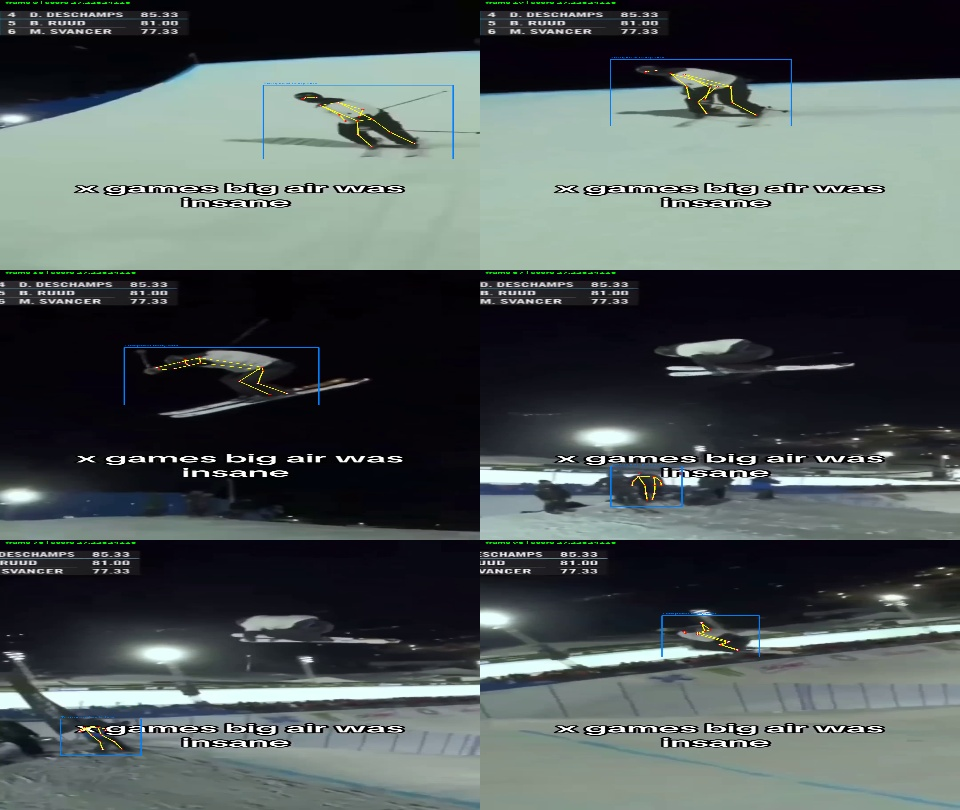

WindowsPath('ski_visual_checks/1026 (1)(2)-14_temporal_contact_sheet.jpg')

In [15]:
import cv2
import numpy as np
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

# reload in case this cell is run before the setup cell in an old kernel
import importlib
import ski_detector
importlib.reload(ski_detector)
from ski_detector import (SkiDetectorCV, BodyAligner, attach_ski_keypoints,
                          draw_skis, pose_keypoints_in_roi,
                          pose_keypoints_detected_roi, bbox_from_keypoints)

# COCO Keypoint Skeleton Connections for visualization
SKELETON_CONNECTIONS = [
    (0, 1), (0, 2), (1, 3), (2, 4),             # Head (Nose, Eyes, Ears)
    (5, 6),                                     # Shoulders
    (5, 7), (7, 9), (6, 8), (8, 10),            # Arms
    (5, 11), (6, 12), (11, 12),                 # Torso
    (11, 13), (13, 15), (12, 14), (14, 16)      # Legs
]


def draw_skeleton(frame, keypoints, confidence_threshold=0.3, thickness=2):
    """Draws keypoints and skeleton lines directly on the full frame."""
    if keypoints is None or len(keypoints) == 0:
        return frame

    kpts = keypoints[0] if keypoints.ndim == 3 else keypoints

    for p1, p2 in SKELETON_CONNECTIONS:
        x1, y1, c1 = kpts[p1]
        x2, y2, c2 = kpts[p2]
        if c1 >= confidence_threshold and c2 >= confidence_threshold:
            cv2.line(frame, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 255), thickness)

    for x, y, conf in kpts:
        if conf >= confidence_threshold:
            cv2.circle(frame, (int(x), int(y)), 4, (0, 0, 255), -1)
            cv2.circle(frame, (int(x), int(y)), 2, (255, 255, 255), -1)

    return frame


def visualize_single_video_pipeline(labels_df, video_index=0, save_video=False,
                                   show_window=True, output_dir="ski_visual_checks"):
    """
    Runs the pipeline on one clip and draws:
      - blue box   : tracked skier ROI
      - yellow/red : remapped body keypoints
      - magenta    : detected skis (green dot = tip, label = angle)
      - inset      : the 640x640 crop fed to the pose model
    Writes an .mp4 and a 6-frame contact sheet; no GUI required.
    """
    if labels_df.empty:
        print("[ERROR] labels DataFrame is empty.")
        return

    if USE_TEMPORAL_TRACKING:
        from temporal_tracker import visualize_temporal_tracking
        return visualize_temporal_tracking(
            labels_df, video_index=video_index, output_dir=output_dir,
            save_video=save_video, max_gap=TEMPORAL_MAX_GAP)

    sample_row = labels_df.iloc[video_index]
    video_path = sample_row["video_path"]
    target_score = sample_row["target"]
    stem_name = Path(video_path).stem

    print(f"\n--- Visualizing Video [{video_index + 1}/{len(labels_df)}]: {stem_name} ---")
    print(f"File Path: {video_path}")
    print(f"Ground Truth Score: {target_score}")

    pipeline = DynamicPersonTracker(pose_model_path="yolov8n-pose.pt")
    ski_detector = SkiDetectorCV(align_body=False, flow_propagation=True) if DETECT_SKIS else None
    align_pose = bool(globals().get("ALIGN_POSE_ROI", True))
    pose_aligner = BodyAligner() if align_pose else None

    entry_idx, entry_frame, init_box = find_skier_entry_frame(video_path, pipeline.model)
    if init_box is None:
        print(f"[FAIL] No skier detected during entry scan of {stem_name}")
        return

    print(f"[SUCCESS] Skier detected entering at Frame {entry_idx}")
    pipeline.init_tracker(entry_frame, init_box)

    cap = cv2.VideoCapture(str(video_path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, entry_idx)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0

    out_dir = Path(output_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    writer = None
    contact_sheet = []

    if show_window:
        cv2.namedWindow(f"YOLO Pose + Skis - {stem_name}", cv2.WINDOW_NORMAL)

    frame_count = entry_idx
    ski_frames = 0
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        display_frame = frame.copy()
        crop_inset = np.zeros((160, 160, 3), dtype=np.uint8)
        frame_kpts = np.zeros((17, 3), dtype=np.float32)
        ski_result = {"skis": []}

        if USE_DETECTED_ROI_POSE:
            frame_kpts, pose_bbox = pose_keypoints_detected_roi(
                pipeline.model, frame, prev_bbox=pipeline.bbox,
                aligner=pose_aligner if align_pose else None,
                conf_thres=POSE_CONF, bbox_pad=BODY_BOX_PAD)
            if frame_kpts[:, 2].max() > 0 and pose_bbox is not None:
                bbox = pose_bbox
                pipeline.bbox = bbox
                tracking_ok = True
            else:
                bbox = pipeline.bbox
                tracking_ok = False
        else:
            bbox, tracking_ok = pipeline.update(frame)
            if not tracking_ok:
                tracking_ok = pipeline.recover_target(frame, pipeline.bbox)
                bbox = pipeline.bbox if tracking_ok else None
            if tracking_ok and bbox is not None:
                frame_kpts = pose_keypoints_in_roi(
                    pipeline.model, frame, bbox,
                    aligner=pose_aligner if align_pose else None)

        if tracking_ok and bbox is not None:
            x, y, w, h = [int(v) for v in bbox]
            h_f, w_f = frame.shape[:2]
            margin = 0.15
            x1 = max(0, int(x - w * margin))
            y1 = max(0, int(y - h * margin))
            x2 = min(w_f, int(x + w * (1 + margin)))
            y2 = min(h_f, int(y + h * (1 + margin)))
            inset_crop = frame[y1:y2, x1:x2]
            if inset_crop.size:
                crop_inset = cv2.resize(inset_crop, (160, 160))

            if frame_kpts[:, 2].max() > 0:
                display_frame = draw_skeleton(display_frame, frame_kpts[None, ...])

            if DETECT_SKIS and ski_detector is not None:
                ski_result = ski_detector.detect(
                    frame, bbox, frame_kpts if frame_kpts[:, 2].max() > 0 else None)
                draw_skis(display_frame, ski_result)
            if ski_result["skis"]:
                ski_frames += 1

            cv2.rectangle(display_frame, (x1, y1), (x2, y2), (255, 128, 0), 2)
            cv2.putText(display_frame, f"Tracked ROI ({w}x{h})", (x1, max(20, y1 - 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 128, 0), 2)
        else:
            cv2.putText(display_frame, "STATUS: TARGET LOST", (30, 80),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

        display_frame[10:170, 10:170] = crop_inset
        cv2.rectangle(display_frame, (10, 10), (170, 170), (255, 255, 255), 1)
        cv2.putText(display_frame, "Model Input Crop", (15, 165),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1)
        cv2.putText(display_frame, f"Frame: {frame_count} | Target: {target_score} | skis: {len(ski_result['skis'])}",
                    (180, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        if save_video:
            if writer is None:
                fourcc = cv2.VideoWriter_fourcc(*"mp4v")
                writer = cv2.VideoWriter(
                    str(out_dir / f"{stem_name}_ski_check.mp4"), fourcc, fps,
                    (display_frame.shape[1], display_frame.shape[0]))
            writer.write(display_frame)

        if frame_count % 12 == 0 and len(contact_sheet) < 6:
            thumb = cv2.resize(display_frame, (480, 270))
            contact_sheet.append(thumb)

        if show_window:
            cv2.imshow(f"YOLO Pose + Skis - {stem_name}", display_frame)
            key = cv2.waitKey(30) & 0xFF
            if key == ord("q") or key == 27:
                break
            elif key == ord(" "):
                cv2.waitKey(0)

        frame_count += 1

    cap.release()
    if writer is not None:
        writer.release()
    if show_window:
        cv2.destroyAllWindows()

    if contact_sheet:
        while len(contact_sheet) < 6:
            contact_sheet.append(np.zeros_like(contact_sheet[0]))
        sheet = np.vstack([np.hstack(contact_sheet[i:i + 2]) for i in range(0, 6, 2)])
        sheet_path = out_dir / f"{stem_name}_ski_contact_sheet.jpg"
        cv2.imwrite(str(sheet_path), sheet)
        print(f"[SAVED] {sheet_path}")

    total = max(1, frame_count - entry_idx)
    print(f"[DONE] skis detected in {ski_frames}/{total} frames "
          f"({100.0 * ski_frames / total:.0f}%)")

    # show the contact sheet inline when running in Jupyter
    try:
        from IPython.display import Image, display
        if contact_sheet:
            display(Image(filename=str(sheet_path)))
    except Exception:
        pass

DATA_DIR = Path("C:/Users/franc/Downloads/AQA-7/AQA-7/Actions/ski_big_air")
OUTPUT_DIR = Path("roi_pose_dataset")
SKI_OUTPUT_DIR = Path("ski_dataset")   # one .npz of ski tracks per video
DETECT_SKIS = False                    # B1: ski detection is disabled (unreliable)
USE_DETECTED_ROI_POSE = True           # detect person per frame, then refine pose on their ROI
POSE_CONF = 0.1                        # low threshold needed for 320x240 AQA clips
BODY_BOX_PAD = 0.25                    # pad the pose-derived body box by 25%
USE_TEMPORAL_TRACKING = True           # offline Viterbi stitching + gap filling
TEMPORAL_MAX_GAP = 15                  # max frames to bridge between detections
OVERWRITE_POSE = True                  # regenerate pose arrays with temporal tracking
OVERWRITE_SKI = False                  # True re-processes clips that already have skis
ALIGN_POSE_ROI = True                  # rotate the pose crop with the skier's body axis
SKI_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def resolve_video(stem, data_dir=DATA_DIR):
    """Return the first existing video file for a label stem, else None."""
    stem = str(stem)
    candidates = (
        data_dir / f"{stem}.mp4",
        data_dir / f"{stem.zfill(3)}.mp4",
        data_dir / f"{stem.zfill(3)}.avi",
        data_dir / f"{stem}.avi",
    )
    return next((p for p in candidates if p.is_file()), None)

labels = pd.read_csv(DATA_DIR / "labels_CV.csv", sep=",")
labels["video_path"] = labels["filename"].map(resolve_video)
# Index 225 is one of the 1920x1080 .mp4 clips. Set show_window=True for live playback.
visualize_single_video_pipeline(labels, video_index=188, save_video=True, show_window=True)


## Measured effect of the improvements

A/B on two 1920×1080 clips (`1026 (1)(2)-16`, `-36`), ~130 frames each, same tracker:

| Configuration | Pose frames (16 / 36) | Ski frames (16 / 36) |
|---|---|---|
| baseline (axis-aligned pose, no flow) | 44 / 44 | 56% / 40% |
| body-aligned pose + flow (current) | **62 / 92** | **57% / 76%** |
| body-aligned pose + body-aligned ski ROI + flow | 93 / 90 | 62% / 49% |

Conclusion: rotating the **pose** crop is the big win; rotating the **ski** detector's own crop is not
(a body-relative angle prior throws away legitimate grab poses). Hence `ALIGN_POSE_ROI=True` and
`SkiDetectorCV(align_body=False)`.

## Chosen approach: B1 body-only (active)

After visual review, the active pipeline uses **B1 body-only**: the stock 17-keypoint COCO pose
pipeline that detects the person on the **full frame**, then refines pose on their ROI crop.

* body keypoints: `yolov8n-pose.pt` via `pose_keypoints_detected_roi()`
* person identity: nearest detected person to the previous padded body box
* body box: `bbox_from_keypoints()` with `BODY_BOX_PAD = 0.25` (25% padding)
* output: `<stem>_pose.npy` (17 body joints). `<stem>_pose21.npy` is still written for backwards
  compatibility, but the four ski columns are zero.

Why body-only:

* the classical ski detector is unreliable across clips, so ski-derived features were mostly noise;
* the CSRT ROI sometimes loses the skier while full-frame YOLO pose remains accurate;
* the tracker box is often tighter than the full body (feet/head clipped). Running pose on the full
  frame removes both the ROI-drift and tight-box failure modes.

`DETECT_SKIS = False` and `USE_DETECTED_ROI_POSE = True` in the configuration cell. Set
`USE_DETECTED_ROI_POSE = False` to return to the older CSRT/tracker ROI pipeline for comparison.

### Temporal layer

The per-frame detector can still alternate between a correct box and `TARGET LOST`. The active
pipeline now runs an offline Viterbi track over all person candidates (`temporal_tracker.py`),
fills short gaps by interpolation, and refines pose on the interpolated boxes. This lets a
confident detection later in the clip stabilise the track through weak frames earlier. Set
`USE_TEMPORAL_TRACKING = False` to disable it.

No 21-keypoint training is required for this path. The failed 21-keypoint experiment showed that
training a large custom pose model from scratch on ~800 pseudo-labelled frames produced unusable
keypoints (pose mAP50 ~0.0017), so it is not used here.

If body keypoints turn out to be weak on low-resolution clips, fine-tune **only** the 17-keypoint
`yolov8n-pose.pt` on verified frames (option B2). Do not train a 21-keypoint model from scratch.